<div style="border-radius:10px; border:black solid; padding: 15px; background-color: Green; font-size:100%; text-align:left">
<p style="font-family:Georgia; font-weight:bold; letter-spacing: 2px; color:white; font-size:200%; text-align:center;padding: 0px;"> Banking Churn Analysis & Modeling.</p></div>

<div align="center">
  <img src="https://m.economictimes.com/thumb/msid-100281493,width-1200,height-900,resizemode-4,imgsize-14062/banks-request-rbi-for-more-time-for-new-loan-provisioning-system.jpg" alt="Image Description" width="300" height="200">
</div>

<div style="border-radius:10px; border:#808080 solid; padding: 15px; background-color: ##F0E68C ; font-size:100%; text-align:left">

<h3 align="left"><font color=brown>📊 Business Objective:</font></h3>
   
- The goal would be to identify which customers are most likely to churn (leave the service) and understand the key factors driving their decision to leave. `Churn Reduction through Predictive Analytics`
- Churn refers to the process by which a customer stops doing business with a company.

<h3 align="left"><font color=brown>📊 Business Value:</font></h3>
- Customer retention is critical for a bank’s profitability. Predicting which customers are likely to churn can help the bank take proactive steps (e.g., offering personalized services or incentives) to retain valuable customers.

## **Import Needded Columns**

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
sns.set(style="darkgrid",font_scale=1.5)
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, ExtraTreesClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score ,f1_score, confusion_matrix, classification_report

## **Data Representation**

In [2]:
# Read data
df = pd.read_csv('Churn_Modelling.csv')

In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


* **RowNumber**: Index of the row.
* **CustomerId**: Unique identifier for each customer.
* **Surname**: Customer's last name (may not be very useful for analysis).
* **CreditScore**: The credit score of the customer [300 : 850].
    - Poor credit: 300 to 579.
    - Fair credit: 580 to 669.
    - Good credit: 670 to 739.
    - Very good credit: 740 to 799.
    - Excellent credit: 800 to 850.
* **Geography**: Country of the customer (e.g., France, Spain).
* **Gender**: Gender of the customer (e.g., Male, Female).
* **Age**: Age of the customer.
* **Tenure**: Number of years the customer has been with the bank.
* **Balance**: Account balance of the customer.
* **NumOfProducts**: Number of products the customer has purchased.
* **HasCrCard**: Whether the customer has a credit card (1 = Yes, 0 = No).
* **IsActiveMember**: Whether the customer is an active member (1 = Yes, 0 = No).
* **EstimatedSalary**: Estimated annual salary of the customer.
* **Exited**: Whether the customer left the bank (1 = Yes, 0 = No) — this is likely the target for churn prediction.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


## **Data Wrangling**

**Check Duplicated Values**

In [5]:
df.duplicated().sum()

0

**Check Missing Values**

In [6]:
df.isna().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

**Check Outliers Values**

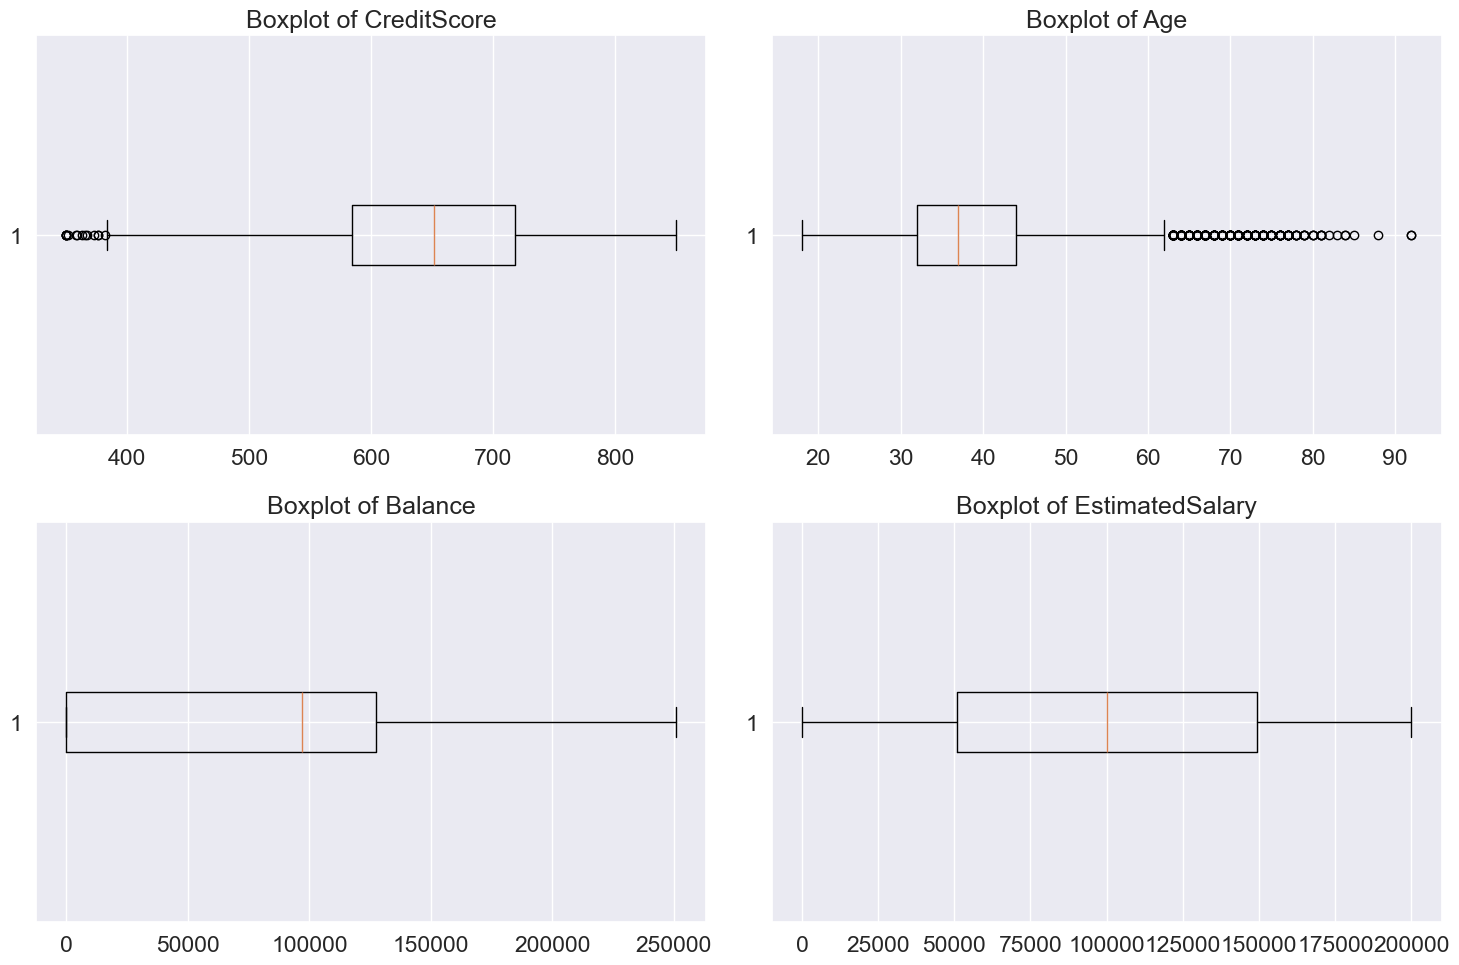

In [7]:
# Features to check for outliers
numerical_features = ['CreditScore', 'Age', 'Balance', 'EstimatedSalary']

# Create box plots for each feature to visually inspect outliers
plt.figure(figsize=(15, 10))
for i, feature in enumerate(numerical_features, 1):
    plt.subplot(2, 2, i)
    plt.boxplot(df[feature], vert=False)
    plt.title(f'Boxplot of {feature}')
    
plt.tight_layout()
plt.show()

## **Exploratory Data Analysis**

- **The goal of EDA is to better understand the distributions of features, identify trends or patterns, and explore relationships between features and the target variable (Exited)**

#### **Univariate Analysis**

**CreditScore Column**

In [8]:
df['CreditScore'].describe()

count    10000.000000
mean       650.528800
std         96.653299
min        350.000000
25%        584.000000
50%        652.000000
75%        718.000000
max        850.000000
Name: CreditScore, dtype: float64

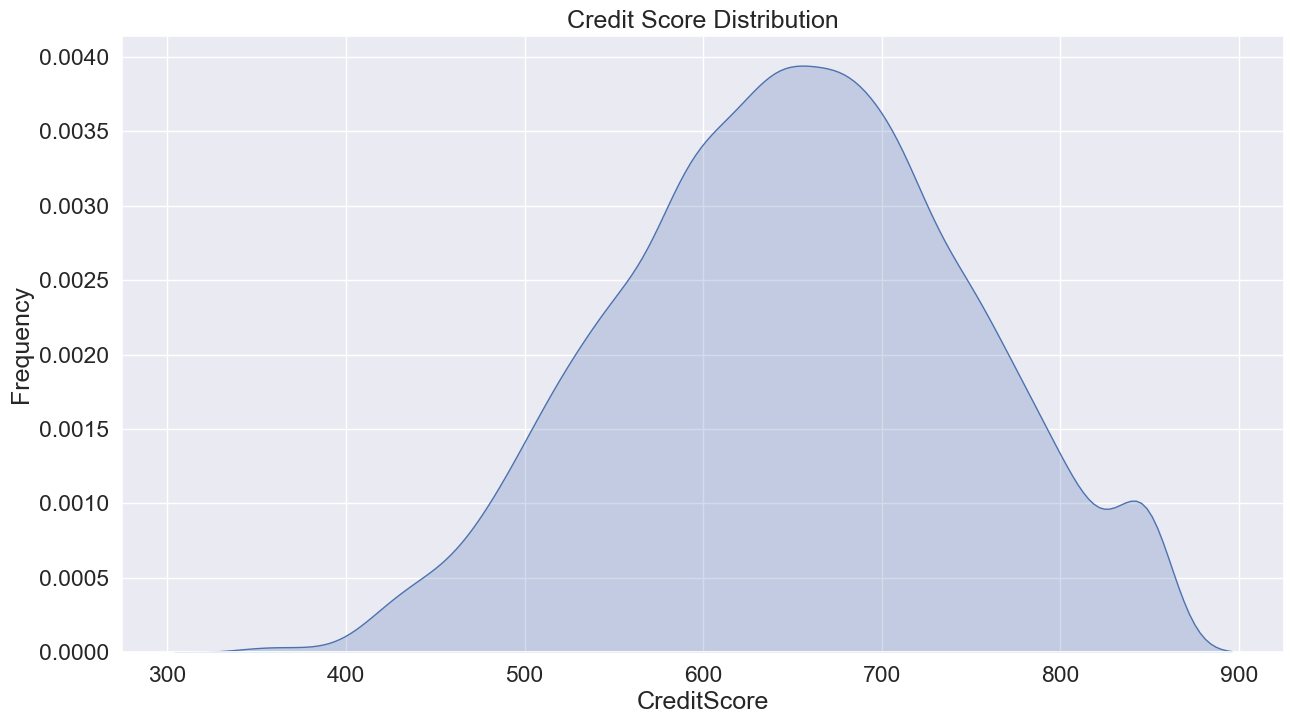

In [9]:
plt.figure(figsize=(15, 8))

sns.kdeplot(df['CreditScore'], fill=True, palette="Set2")
plt.title('Credit Score Distribution')
plt.xlabel('CreditScore')
plt.ylabel('Frequency')

plt.show()

- The distribution of credit scores is slightly skewed to the right, meaning more customers have higher credit scores (closer to 800).
- This could indicate that most customers have a good credit history.

**Geography Column**

In [10]:
df["Geography"].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

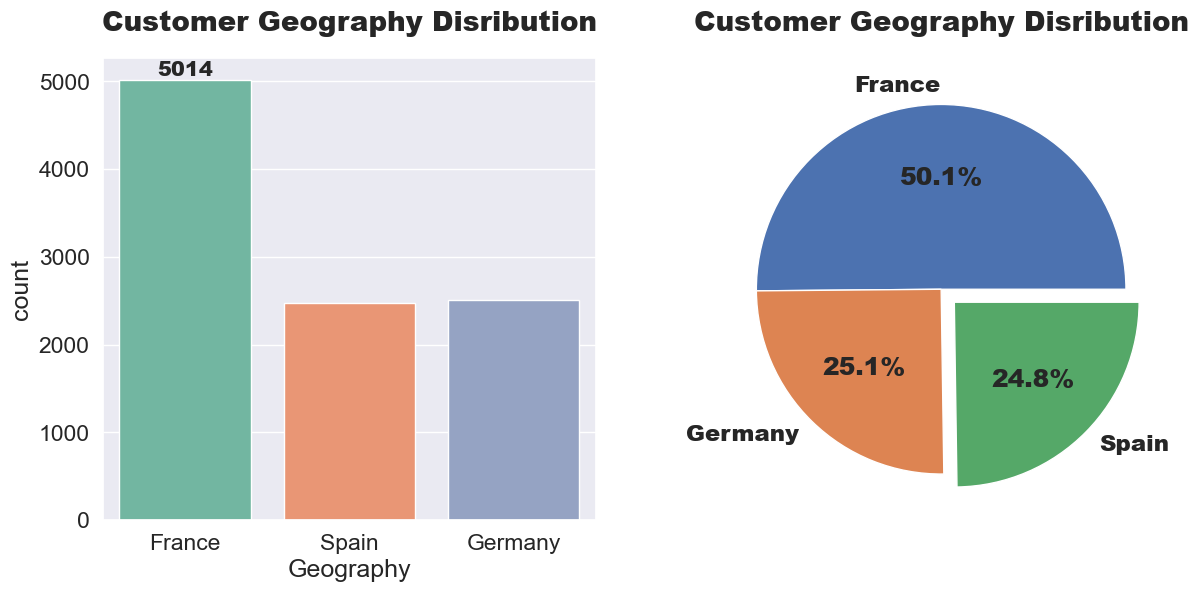

In [11]:
count = df["Geography"].value_counts()

plt.figure(figsize=(14,6))
plt.subplot(1,2,1)
ax=sns.countplot(data=df, x="Geography",palette="Set2")
ax.bar_label(ax.containers[0],fontweight="black",size=15)
plt.title("Customer Geography Disribution",fontweight="black",size=20,pad=20)

plt.subplot(1,2,2)
plt.pie(count.values, labels=count.index, autopct="%1.1f%%",colors=sns.set_palette("Set2"),
        textprops={"fontweight":"black"},explode=[0, 0,0.1])
plt.title("Customer Geography Disribution",fontweight="black",size=20,pad=20)
plt.show()

**Gender Column**

In [12]:
df["Gender"].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

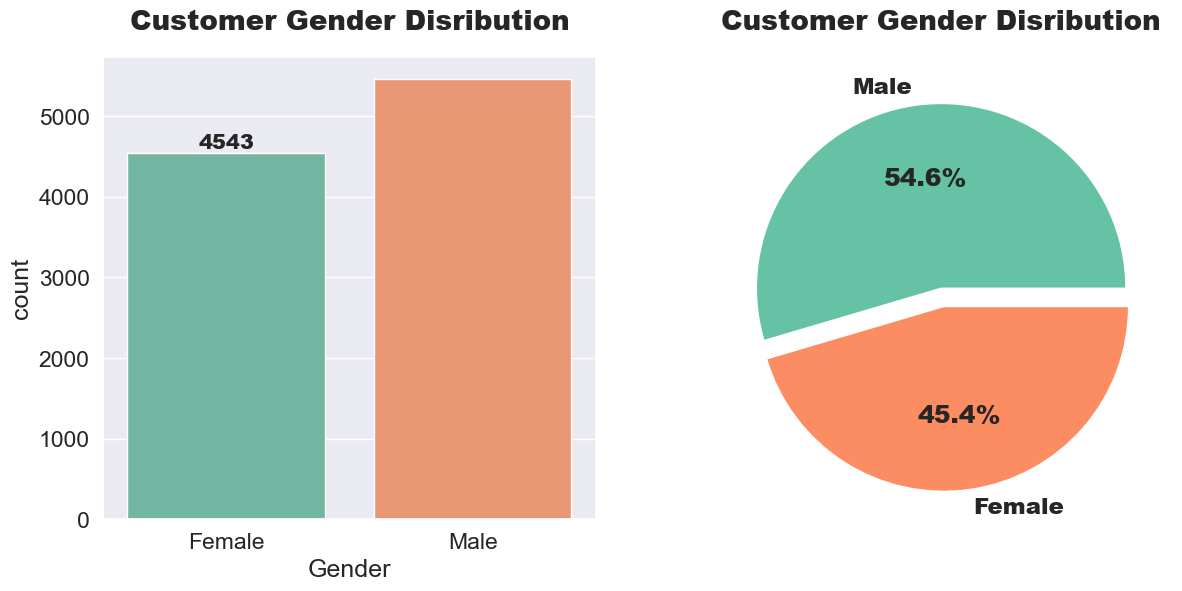

In [13]:
count = df["Gender"].value_counts()

plt.figure(figsize=(14,6))
plt.subplot(1,2,1)
ax=sns.countplot(data=df, x="Gender",palette="Set2")
ax.bar_label(ax.containers[0],fontweight="black",size=15)
plt.title("Customer Gender Disribution",fontweight="black",size=20,pad=20)

plt.subplot(1,2,2)
plt.pie(count.values, labels=count.index, autopct="%1.1f%%",colors=sns.set_palette("Set2"),
        textprops={"fontweight":"black"},explode=[0, 0.1])
plt.title("Customer Gender Disribution",fontweight="black",size=20,pad=20)
plt.show()

**NumOfProducts Column**

In [19]:
df["NumOfProducts"].value_counts()

NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

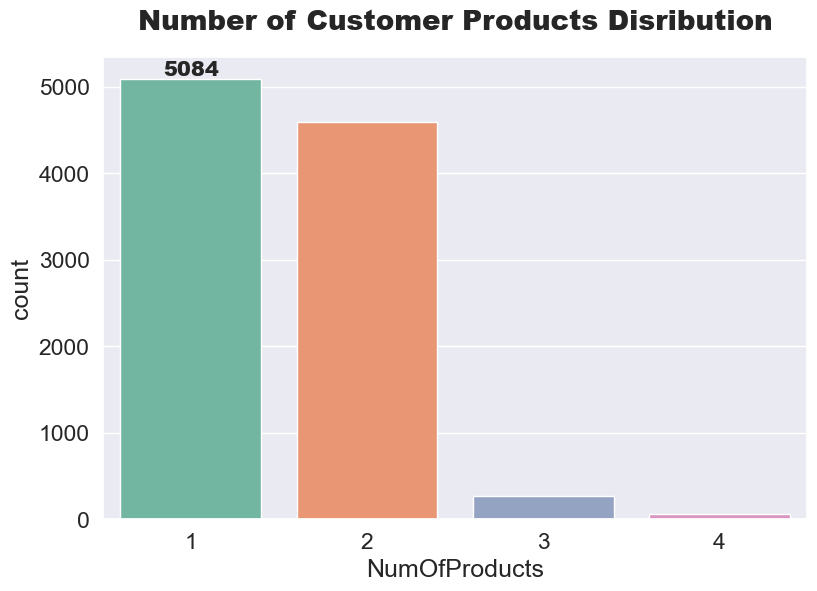

In [20]:
count = df["NumOfProducts"].value_counts()

plt.figure(figsize=(20,6))
plt.subplot(1,2,1)
ax=sns.countplot(data=df, x="NumOfProducts",palette="Set2")
ax.bar_label(ax.containers[0],fontweight="black",size=15)
plt.title("Number of Customer Products Disribution",fontweight="black",size=20,pad=20)

plt.show()

**Multivariate Analysis**

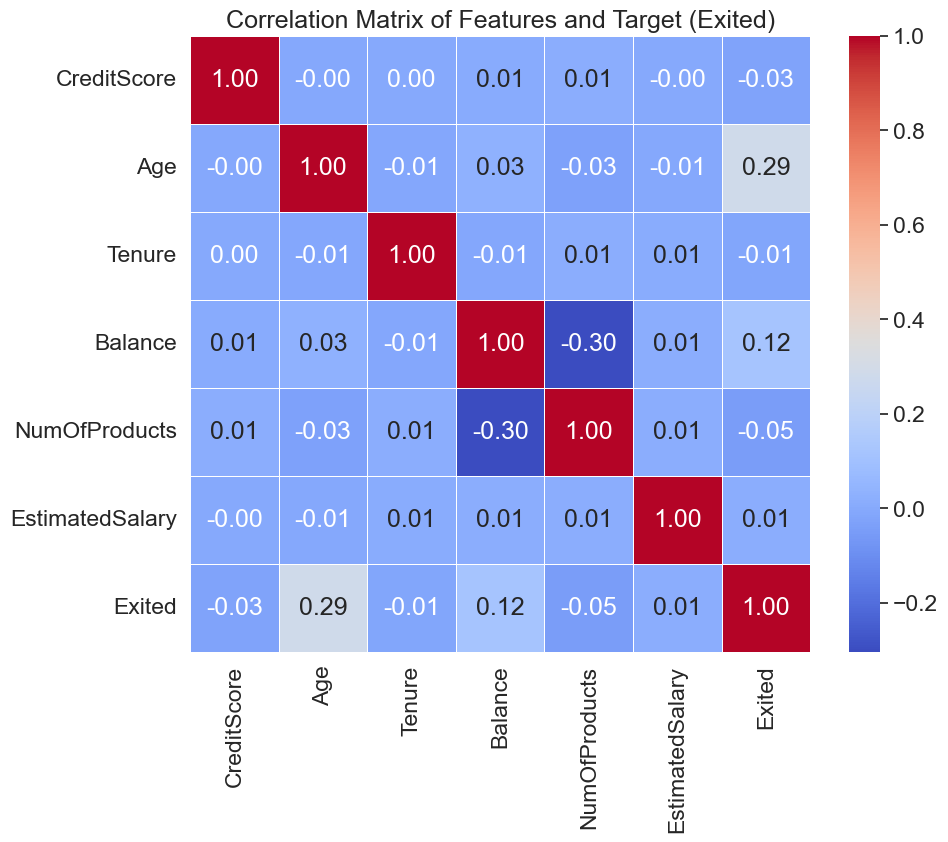

In [31]:
# Include the target 'Exited' and numerical features for correlation analysis
numerical_features_with_target = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary', 'Exited']

# Compute the correlation matrix
correlation_matrix = df[numerical_features_with_target].corr()

# Plot the correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Features and Target (Exited)')
plt.show()

## **Data Preprocessing**

**Drop Unneeded Columns**

In [32]:
df.drop(columns=['RowNumber', 'CustomerId', 'Surname'], inplace=True)

**Define Features `X` and Target `y`**

In [33]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

**Data Encoding**

**To apply encoding to categorical columns in your dataset, the type of encoding will depend on whether the categorical variables are nominal (unordered) or ordinal (ordered)**

In [34]:
X = pd.get_dummies(X, columns=['Geography', 'Gender'], drop_first=False)

In [35]:
X.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,True,False,False,True,False
1,608,41,1,83807.86,1,0,1,112542.58,False,False,True,True,False
2,502,42,8,159660.80,3,1,0,113931.57,True,False,False,True,False
3,699,39,1,0.00,2,0,0,93826.63,True,False,False,True,False
4,850,43,2,125510.82,1,1,1,79084.10,False,False,True,True,False


**Data Scaling**

In [36]:
# Initialize the scaler
scaler = StandardScaler()

# Apply scaling to numerical columns
numerical_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary']
X[numerical_cols] = scaler.fit_transform(X[numerical_cols])

**Data Splitting**

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**Data Balancing**
- We can apply SMOTE model to balance the data.

In [38]:
# # Initialize SMOTE
# smote = SMOTE(random_state=42)

# # Apply SMOTE to the training data
# X_train, y_train = smote.fit_resample(X_train, y_train)

# # Check the new shapes of the resampled data
# print("Resampled X_train shape:", X_train.shape)
# print("Resampled y_train shape:", y_train.shape)

## **Machine Learning Models**

**Logistic Regression model**

In [39]:
lr = LogisticRegression(penalty='l2', C=1.0, max_iter=1000)

# Train the model
lr.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [40]:
# Train Score
print(lr.score(X_train, y_train))

0.81125


In [41]:
# Test Score
print(lr.score(X_test, y_test))

0.811


In [42]:
# Make predictions on the test set
y_pred = lr.predict(X_test)

In [43]:
# Get our metrics
lr_acc = accuracy_score(y_test, y_pred)
lr_per = precision_score(y_test, y_pred)
lr_rec = recall_score(y_test, y_pred)

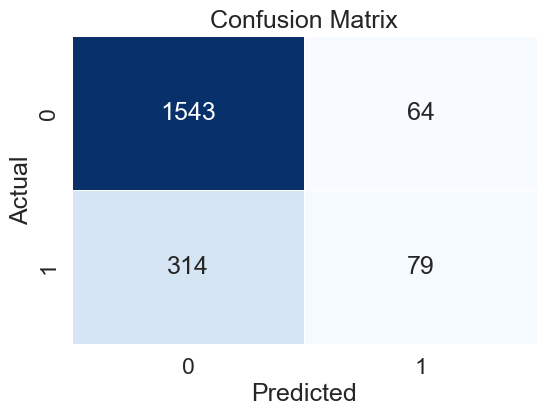

In [44]:
# Create a confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Visualize the confusion matrix with a heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', linewidths=.5, cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

**SVC Model**

In [45]:
# Define hyperparameter grid
param_grid = {'kernel': ['linear', 'poly', 'rbf'],
              'C': [0.1, 1, 10]}

svm = SVC()

In [46]:
# Perform Grid Search with cross-validation
grid_search = GridSearchCV(svm, param_grid, cv=5)
grid_search.fit(X, y)

,estimator,SVC()
,param_grid,"{'C': [0.1, 1, ...], 'kernel': ['linear', 'poly', ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,10


In [47]:
# Get best model
best_model = grid_search.best_estimator_
best_model

,C,10
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [48]:
# Train Score
print(best_model.score(X_train, y_train))

0.881375


In [49]:
# Test Score
print(best_model.score(X_test, y_test))

0.882


In [50]:
y_pred = best_model.predict(X_test)

In [51]:
# Get our metrics
svc_acc = accuracy_score(y_test, y_pred)
svc_per = precision_score(y_test, y_pred)
svc_rec = recall_score(y_test, y_pred)

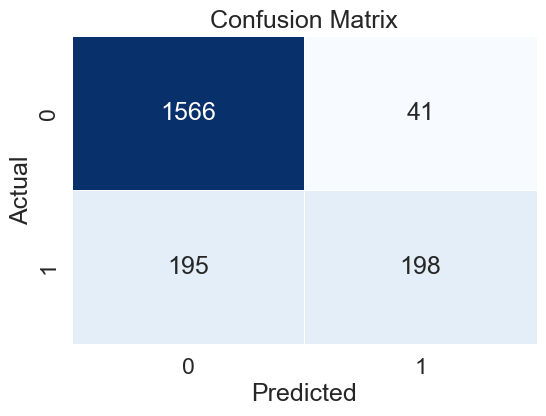

In [52]:
# Create a confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Visualize the confusion matrix with a heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', linewidths=.5, cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

**Decision Tree Classifier**

In [53]:
clf = DecisionTreeClassifier(max_depth=4, min_impurity_decrease=0.01, random_state=42)

# Train the model
clf.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.01
,class_weight,None


In [54]:
# Train Score
print(clf.score(X_train, y_train))

0.840125


In [55]:
# Test Score
print(clf.score(X_test, y_test))

0.844


In [56]:
# Make predictions on the test set
y_pred = clf.predict(X_test)

In [57]:
# Get our metrics
clf_acc = accuracy_score(y_test, y_pred)
clf_per = precision_score(y_test, y_pred)
clf_rec = recall_score(y_test, y_pred)

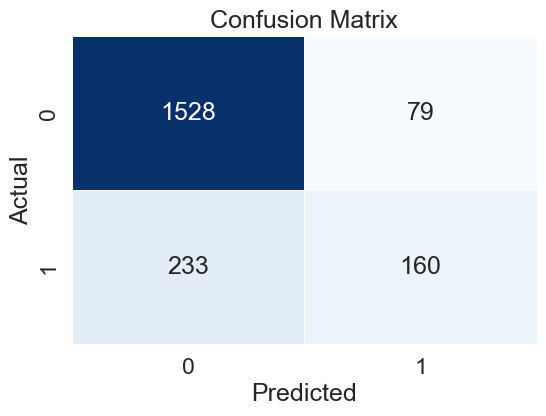

In [58]:
# Create a confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Visualize the confusion matrix with a heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', linewidths=.5, cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

**RandomForestClassifier Model**

In [59]:
RF_classifier = RandomForestClassifier(n_estimators=100, min_impurity_decrease=0.01)

RF_classifier.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.01
,bootstrap,True
,oob_score,False


In [60]:
# Train score
RF_classifier.score(X_train, y_train)

0.7945

In [61]:
# Test score
RF_classifier.score(X_test, y_test)

0.8035

In [62]:
# Get prediction
y_pred = RF_classifier.predict(X_test)

In [63]:
# Get our metrics
rf_acc = accuracy_score(y_test, y_pred)
rf_per = precision_score(y_test, y_pred)
rf_rec = recall_score(y_test, y_pred)

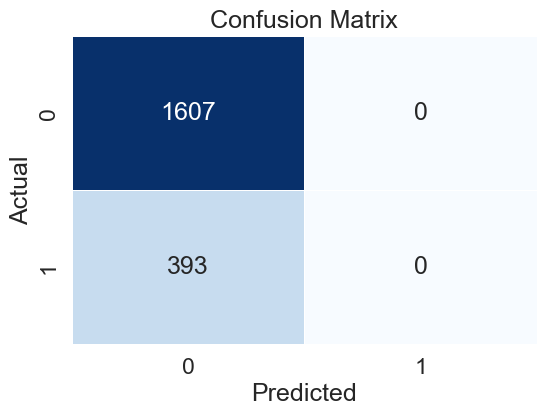

In [64]:
# Create a confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Visualize the confusion matrix with a heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', linewidths=.5, cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

**XGBClassifier Model**

In [65]:
# Create XGBClassifier Model
XGB_classifier = XGBClassifier(n_estimators=200)

XGB_classifier.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [66]:
# Train score
XGB_classifier.score(X_train, y_train)

0.9915

In [67]:
# Test score
XGB_classifier.score(X_test, y_test)

0.86

In [68]:
# Get prediction
y_pred_xgb = XGB_classifier.predict(X_test)

In [69]:
# Get our metrics
xgb_acc = accuracy_score(y_test, y_pred_xgb)
xgb_per = precision_score(y_test, y_pred_xgb)
xgb_rec = recall_score(y_test, y_pred_xgb)

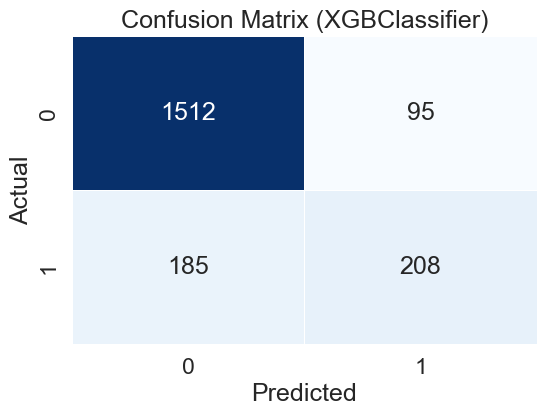

In [70]:
# Create a confusion matrix for XGBClassifier
conf_matrix_xgb = confusion_matrix(y_test, y_pred_xgb)

# Visualize the confusion matrix with a heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix_xgb, annot=True, fmt='d', cmap='Blues', linewidths=.5, cbar=False)
plt.title('Confusion Matrix (XGBClassifier)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### **Evaluation**

<div style="border-radius:10px; border:#808080 solid; padding: 15px; background-color: ##F0E68C ; font-size:100%; text-align:left">

<h3 align="left"><font color=brown>📊 Key Metrics:</font></h3>
    
- **`Accuracy:`**
    - Measures the overall correctness of the model (the percentage of correct predictions).
    - Accuracy is not the most important metric in imbalanced datasets, as it can be misleading. For example, predicting the majority class most of the time will give high accuracy but poor performance on the minority class (churners).


- **`Precision:`**
    - Precision answers the question: Of all the customers predicted to churn, how many actually churned?
    - High precision means fewer false positives (customers predicted to churn but actually don’t).


- **`Recall:`**
    - Recall answers the question: Of all the customers that actually churned, how many did the model correctly identify?
    - High recall means fewer false negatives (customers that churn but were predicted not to).

In [71]:
Models = ['LogisticRegression', 'SVC', 'DecisionTreeClassifier', 'RandomForestClassifier', 'XGBoostClassifier']
Accuracy = [lr_acc, svc_acc, clf_acc, rf_acc, xgb_acc]
Precision = [lr_per, svc_per, clf_per, rf_per, xgb_per]
Recall = [lr_rec, svc_rec, clf_rec, rf_rec, xgb_rec]

models = pd.DataFrame(data={'Models': Models,'Accuracy': Accuracy, 'Precision': Precision, 'Recall': Recall})
models

,Models,Accuracy,Precision,Recall
0,LogisticRegression,0.8110,0.552448,0.201018
1,SVC,0.8820,0.828452,0.503817
2,DecisionTreeClassifier,0.8440,0.669456,0.407125
3,RandomForestClassifier,0.8035,0.000000,0.000000
4,XGBoostClassifier,0.8600,0.686469,0.529262


<div style="border-radius:10px; border:#808080 solid; padding: 15px; background-color: ##F0E68C ; font-size:100%; text-align:left">

<h3 align="left"><font color=brown>📊 Inference:</font></h3>
    
**LogisticRegression:**
- `Accuracy:` 0.8115, `Precision:` 0.5563, `Recall:` 0.2010
- `Observation:` Despite a reasonable accuracy, the low recall indicates that it’s missing a lot of churners. The model struggles with identifying the minority class.


**SVC:**
- `Accuracy:` 0.8820, `Precision:` 0.8284, `Recall:` 0.5038
- `Observation:` This model performs well, especially in precision, meaning it's confident when predicting churners. However, its recall is only moderate, meaning it's missing some actual churners.


**DecisionTreeClassifier:**
- `Accuracy:` 0.8440, `Precision:` 0.6695, `Recall:` 0.4071
- `Observation:` Moderate precision and recall, indicating a more balanced performance. However, it still misses a significant portion of actual churners.


**RandomForestClassifier:**
- `Accuracy:` 0.8035, `Precision:` 0.0000, `Recall:` 0.0000
- `Observation:` This model is likely predicting only the majority class (non-churners), which is why it has 0 precision and recall. This indicates the model is heavily biased toward the majority class, likely due to class imbalance.


**XGBoostClassifier:**
- `Accuracy:` 0.8575, `Precision:` 0.6742, `Recall:` 0.5318
- `Observation:` XGBoost strikes a balance between precision and recall, identifying more churners than some other models. It’s one of the better-performing models.


<div style="border-radius:10px; border:#808080 solid; padding: 15px; background-color: ##F0E68C ; font-size:100%; text-align:left">

<h3 align="left"><font color=brown>📊 Key Takeaways:</font></h3>
    
**Best Model for Recall:**
- `XGBoostClassifier` (Recall: 0.5318) performed best in terms of recall among the compared models, meaning it identified more churners than the others. Its recall value was still moderate, indicating that many churners were missed.


**Most Balanced Model:**
- `XGBoostClassifier` (Precision: 0.6742, Recall: 0.5318) provided the best balance between precision and recall, making it a strong overall candidate.


**Best Model for Precision:**
- `SVC` had the highest precision (0.8284), meaning it was the most accurate when predicting churners. However, it had lower recall (0.5038), meaning it missed a significant portion of churners.


**Weakest Model:**
- `RandomForestClassifier` (Precision: 0.0000, Recall: 0.0000) predicted only the majority class, showing it was heavily biased by class imbalance and did not identify any churners.


## **Model Deployment**

**Save the Best Model (XGBoostClassifier), Scaler, and Feature Columns**
- `XGBoostClassifier` was selected as the best model to deploy (best balance of accuracy, precision and recall).
- We also save the fitted `StandardScaler` and the training feature column order, since the Streamlit app must preprocess raw user input exactly the same way before predicting.

In [72]:
import joblib

joblib.dump(XGB_classifier, 'xgb_churn_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(list(X.columns), 'feature_columns.pkl')

print("Saved: xgb_churn_model.pkl, scaler.pkl, feature_columns.pkl")

Saved: xgb_churn_model.pkl, scaler.pkl, feature_columns.pkl
